# Analisis Kualitas Air: Prediksi Kelayakan Minum (*Potability*)

**Dataset:** `water_quality_potability.csv` (10.000 sampel, 9 parameter kimia/fisika + 1 label).

**Pertanyaan yang ingin dijawab:**
1. Bagaimana kondisi data (kelengkapan, distribusi, outlier)?
2. Parameter apa yang paling membedakan air layak minum (`Potability = 1`) dan tidak layak (`0`)?
3. Seberapa baik model machine learning memprediksi kelayakan air?

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
sns.set_theme(style='whitegrid')
df = pd.read_csv('water_quality_potability.csv')
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.160466,195.712338,22636.785632,7.235746,336.794067,424.396711,14.376178,68.105888,3.991681,1
1,7.187738,193.202237,21263.028076,7.117409,333.997161,430.163405,14.206928,64.807703,3.957064,0
2,5.400302,140.739062,17266.593422,10.056852,328.358241,472.874073,11.256381,56.931906,4.824786,0
3,7.078913,196.886558,21539.185679,7.104867,335.223406,429.400333,14.344261,65.289765,3.909317,0
4,7.052283,194.971523,21659.468727,7.101790,335.669903,425.620822,14.100794,66.178504,3.989340,0


## 1. Pemahaman Data

In [2]:
print(df.shape)
df.info()
df.describe().T

(10000, 10)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               10000 non-null  float64
 1   Hardness         10000 non-null  float64
 2   Solids           10000 non-null  float64
 3   Chloramines      10000 non-null  float64
 4   Sulfate          10000 non-null  float64
 5   Conductivity     10000 non-null  float64
 6   Organic_carbon   10000 non-null  float64
 7   Trihalomethanes  10000 non-null  float64
 8   Turbidity        10000 non-null  float64
 9   Potability       10000 non-null  int64  
dtypes: float64(9), int64(1)
memory usage: 781.4 KB


,count,mean,std,min,25%,50%,75%,max
ph,10000.0,7.091423,0.706589,0.227499,7.022816,7.093586,7.161077,14.000000
Hardness,10000.0,196.028208,14.636373,73.492234,194.609577,196.057913,197.460684,317.338124
Solids,10000.0,21984.910331,3895.384413,320.942611,21458.018822,21977.488628,22503.494592,56488.672413
Chloramines,10000.0,7.135162,0.710279,1.390871,7.057332,7.133492,7.215818,13.127000
Sulfate,10000.0,333.063156,18.513111,129.000000,331.124701,333.098363,334.943071,481.030642
Conductivity,10000.0,426.360604,36.080914,201.619737,422.515794,426.246982,429.921153,708.226364
Organic_carbon,10000.0,14.339111,1.484742,2.200000,14.188197,14.335375,14.483844,27.006707
Trihalomethanes,10000.0,66.465396,7.182162,8.577013,65.750893,66.469224,67.200320,124.000000
Turbidity,10000.0,3.972793,0.350731,1.450000,3.935476,3.973391,4.010571,6.494749
Potability,10000.0,0.500000,0.500025,0.000000,0.000000,0.500000,1.000000,1.000000


In [3]:
print('Missing value :', df.isna().sum().sum())
print('Duplikat      :', df.duplicated().sum())
print(df['Potability'].value_counts())

Missing value : 0
Duplikat      : 0
Potability
1    5000
0    5000
Name: count, dtype: int64


**Temuan:** data bersih (tanpa *missing value*) dan **seimbang sempurna** (5.000 layak vs 5.000 tidak layak). Karena seimbang, *accuracy* aman dipakai sebagai metrik utama dan tidak perlu teknik *oversampling*.

## 2. Distribusi Fitur dan Outlier

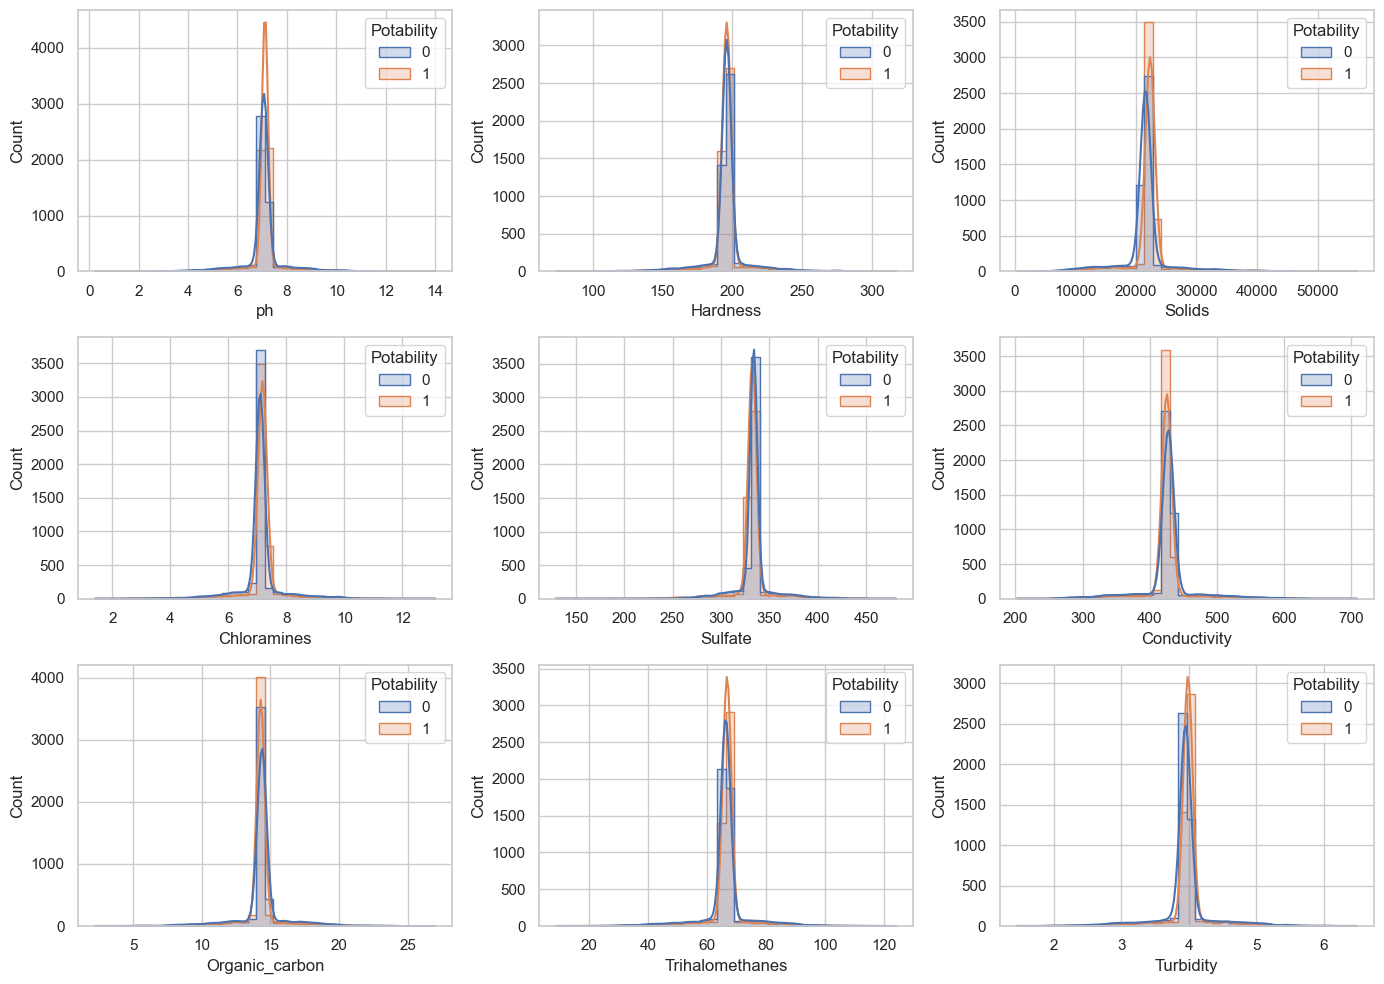

In [4]:
fitur = df.columns.drop('Potability')
fig, axes = plt.subplots(3,3, figsize=(14,10))
for ax,c in zip(axes.ravel(), fitur):
    sns.histplot(data=df, x=c, hue='Potability', kde=True, ax=ax, bins=40, element='step')
plt.tight_layout(); plt.show()

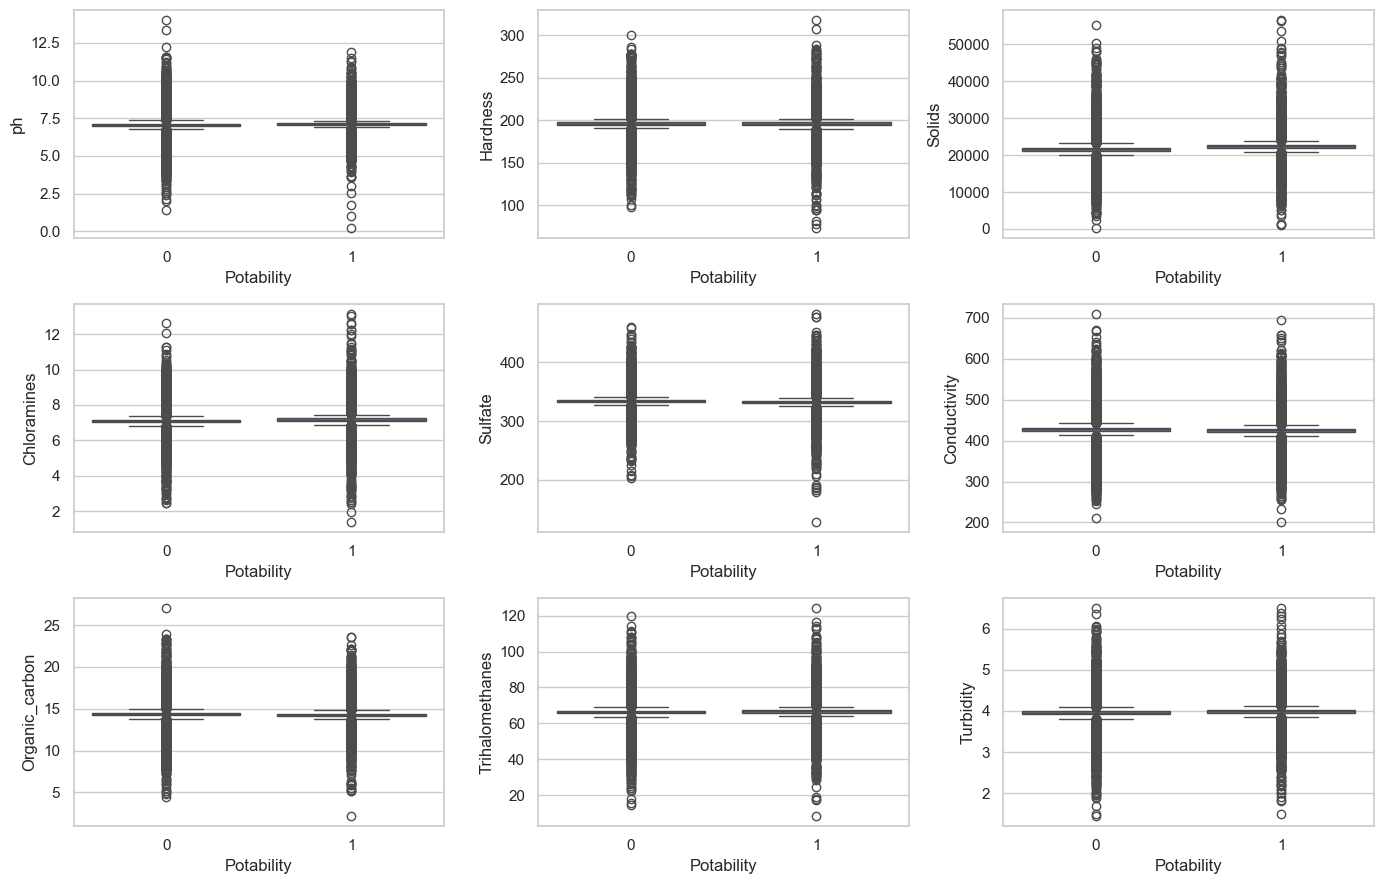

In [5]:
fig, axes = plt.subplots(3,3, figsize=(14,9))
for ax,c in zip(axes.ravel(), fitur):
    sns.boxplot(data=df, x='Potability', y=c, ax=ax)
plt.tight_layout(); plt.show()

**Cara membaca:** jika dua distribusi (layak vs tidak layak) hampir menumpuk sempurna pada suatu fitur, fitur itu lemah dalam membedakan kelas. Perhatikan apakah ada fitur yang puncaknya bergeser antar kelas.

## 3. Korelasi Antar Fitur

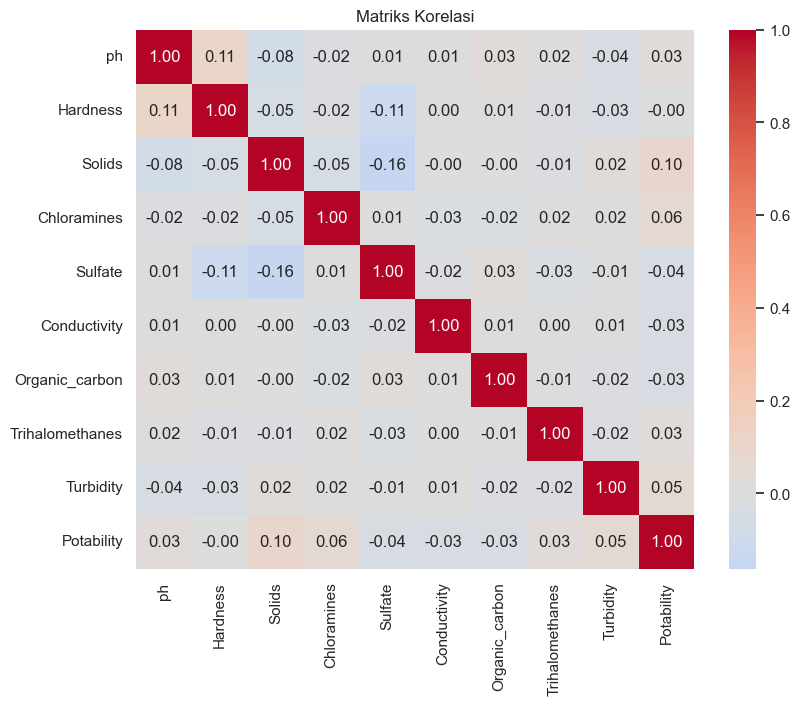

Solids             0.095617
Chloramines        0.058243
Turbidity          0.051648
Sulfate           -0.038707
Conductivity      -0.032677
ph                 0.032668
Organic_carbon    -0.032175
Trihalomethanes    0.029687
Hardness          -0.000324
Name: Potability, dtype: float64

In [6]:
plt.figure(figsize=(9,7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriks Korelasi'); plt.show()
df.corr()['Potability'].drop('Potability').sort_values(key=abs, ascending=False)

**Interpretasi:** korelasi tiap fitur terhadap `Potability` menunjukkan hubungan **linear** saja. Nilai yang kecil belum tentu berarti fitur tak berguna, karena bisa saja hubungannya non-linear atau berupa interaksi antar fitur. Itu sebabnya model non-linear (Random Forest) dicoba di bawah.

## 4. Pemodelan

In [7]:
X, y = df[fitur], df['Potability']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

models = {
  'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
  'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}
hasil = {}
for nama, m in models.items():
    cv = cross_val_score(m, Xtr, ytr, cv=5, scoring='accuracy')
    m.fit(Xtr, ytr)
    pred = m.predict(Xte)
    hasil[nama] = dict(cv_acc=cv.mean(), test_acc=(pred==yte).mean(), auc=roc_auc_score(yte, m.predict_proba(Xte)[:,1]))
pd.DataFrame(hasil).T.round(3)

,cv_acc,test_acc,auc
Logistic Regression,0.819,0.820,0.812
Random Forest,0.845,0.844,0.929


              precision    recall  f1-score   support

 Tidak layak       0.82      0.88      0.85      1000
       Layak       0.87      0.81      0.84      1000

    accuracy                           0.84      2000
   macro avg       0.85      0.84      0.84      2000
weighted avg       0.85      0.84      0.84      2000



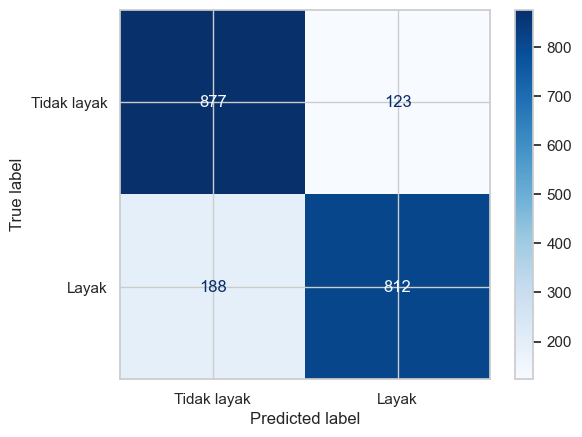

In [8]:
best = models['Random Forest']
pred = best.predict(Xte)
print(classification_report(yte, pred, target_names=['Tidak layak','Layak']))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=['Tidak layak','Layak']).plot(cmap='Blues')
plt.show()

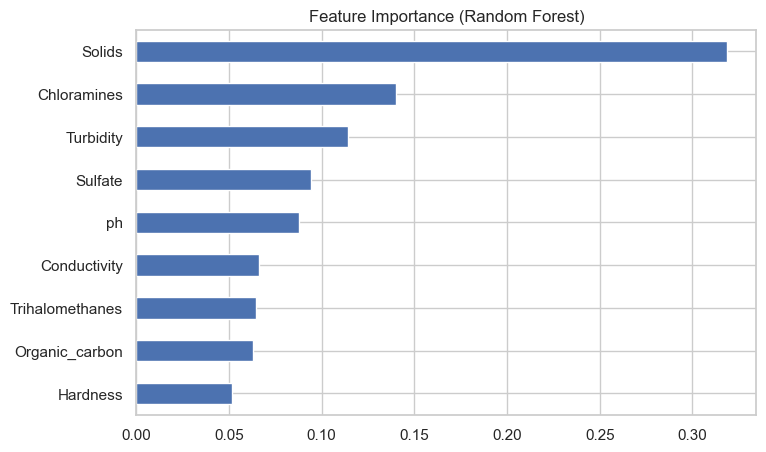

Solids             0.318509
Chloramines        0.140187
Turbidity          0.114278
Sulfate            0.094211
ph                 0.087786
Conductivity       0.065913
Trihalomethanes    0.064479
Organic_carbon     0.062829
Hardness           0.051808
dtype: float64

In [9]:
imp = pd.Series(best.feature_importances_, index=fitur).sort_values()
imp.plot.barh(figsize=(8,5), title='Feature Importance (Random Forest)'); plt.show()
imp.sort_values(ascending=False)

## 5. Kesimpulan
- Data **bersih dan seimbang**, sehingga siap dimodelkan tanpa banyak pra-pemrosesan.
- Logistic Regression hanya mencapai akurasi ± 82%, sedangkan Random Forest ± 84% dengan ROC-AUC ± 0,93 (vs 0,81), sehingga hubungan parameter air dengan kelayakan cenderung **non-linear**.
- Korelasi linear tiap fitur dengan `Potability` sangat kecil (maks ± 0,10 pada `Solids`), namun model tetap berhasil, tanda adanya interaksi antar fitur.
- *Feature importance* menempatkan **Solids** (± 32%) di urutan teratas, diikuti **Chloramines** (± 14%) dan **Turbidity** (± 11%). `Hardness` paling kecil pengaruhnya.
- **Catatan:** kelayakan air minum yang sebenarnya ditentukan standar kesehatan (WHO/Kemenkes), bukan hanya model statistik. Model ini cocok sebagai alat penyaring awal, bukan pengganti uji laboratorium.